# Database basics with SQLite

## Use of AI: can be used, but must be reported.
## AI shall not be used to complete the whole assignment.

Use a library SQLite, which is a built-in library in Python for working with SQLite databases

In [1]:
import sqlite3

## Create table

In [2]:
# Connect to the SQLite database (or create a new one)
conn = sqlite3.connect('Products.db')

In [3]:
# Create a cursor object to interact with the database
cursor = conn.cursor()

In [4]:
# Define the SQL statement to create a table
create_table_sql = '''
CREATE TABLE IF NOT EXISTS products (
    id INTEGER PRIMARY KEY,
    product TEXT,
    value INTEGER);
'''


In [5]:
# Execute the SQL statement to create the table
cursor.execute(create_table_sql)

In [6]:
# Commit the changes and close the connection
conn.commit()
conn.close()

## Insert data to database

In [7]:
# Connect to the database
conn = sqlite3.connect('Products.db')
# Create a cursor object to interact with the database
cursor = conn.cursor()

In [8]:
# Define the SQL statement to insert data into the table
insert_data_sql = '''
INSERT INTO products (id, product, value)
VALUES (?, ?, ?)
'''

In [9]:
# Define the data to be inserted
data_to_insert = (1, 'Violin', 450)
# Execute the SQL statement to insert data
cursor.execute(insert_data_sql, data_to_insert)

In [10]:
data_to_insert = (2, 'Guitar', 500)
cursor.execute(insert_data_sql, data_to_insert)
data_to_insert = (3, 'Harp', 700)
cursor.execute(insert_data_sql, data_to_insert)
data_to_insert = (4, 'Flute', 10)
cursor.execute(insert_data_sql, data_to_insert)

In [11]:
# Commit the changes and close the connection
conn.commit()
conn.close()

## Insert multiple data to database

### Task: find how you can insert multiple instruments in same statement.
- Guidance e.g. in: https://pynative.com/python-sqlite-insert-into-table/
- Hint: executemany()

Add your code so that all the new_instruments are added to the database (using executemany()).

In [12]:
# Connect to the database
conn = sqlite3.connect('Products.db')
# Create a cursor object to interact with the database
cursor = conn.cursor()
# Define the SQL statement to insert data into the table
insert_data_sql = '''
INSERT INTO products (id, product, value)
VALUES (?, ?, ?)
'''

# DO NOT CHANGE THIS
# Define multiple records as a list of tuples
new_instruments = [
    (5, 'Drums', 800),
    (6, 'Piano', 1500),
    (7, 'Saxophone', 650),
    (8, 'Didgeridoo', 300),
    (9, 'Oboe', 600)
]

# YOUR CODE HERE
cursor.executemany(insert_data_sql, new_instruments)

In [13]:
# Commit the changes and close the connection
conn.commit()
conn.close()

## Search from database

In [14]:
# Connect to the database
conn = sqlite3.connect('Products.db')
# Create a cursor object to interact with the database
cursor = conn.cursor()

In [15]:
# Define a search query (SQL SELECT statement)
search_query = "SELECT * FROM products;"

In [16]:
# Execute the search query with the parameter
cursor.execute(search_query)

In [17]:
# Fetch all matching rows
result = cursor.fetchall()

In [18]:
print(result)

[(1, 'Violin', 450), (2, 'Guitar', 500), (3, 'Harp', 700), (4, 'Flute', 10), (5, 'Drums', 800), (6, 'Piano', 1500), (7, 'Saxophone', 650), (8, 'Didgeridoo', 300), (9, 'Oboe', 600)]


In [19]:
# Define a search query based on condition
search_query = "SELECT * FROM products WHERE product = 'Violin';"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(1, 'Violin', 450)]


In [20]:
# Define a search query based on condition
search_query = "SELECT * FROM products WHERE value > 1000;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(6, 'Piano', 1500)]


In [21]:
# Arrange results in order DESC
search_query = "SELECT * FROM products WHERE value > 700 ORDER BY product DESC;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(6, 'Piano', 1500), (5, 'Drums', 800)]


In [22]:
# Arrange results in order ASC
search_query = "SELECT * FROM products ORDER BY product ASC;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(8, 'Didgeridoo', 300), (5, 'Drums', 800), (4, 'Flute', 10), (2, 'Guitar', 500), (3, 'Harp', 700), (9, 'Oboe', 600), (6, 'Piano', 1500), (7, 'Saxophone', 650), (1, 'Violin', 450)]


In [23]:
# Close the cursor and connection
cursor.close()
conn.close()


## Update value in database

In [24]:
conn = sqlite3.connect('Products.db')
cursor = conn.cursor()

In [25]:
update_query = '''
UPDATE products
SET product = 'Guitar', value = 2000
WHERE product = 'Guitar';
'''

In [26]:
cursor.execute(update_query)
conn.commit()

In [27]:
# Check value
search_query = "SELECT * FROM products ORDER BY product ASC;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(8, 'Didgeridoo', 300), (5, 'Drums', 800), (4, 'Flute', 10), (2, 'Guitar', 2000), (3, 'Harp', 700), (9, 'Oboe', 600), (6, 'Piano', 1500), (7, 'Saxophone', 650), (1, 'Violin', 450)]


In [28]:
# Close the cursor and connection
cursor.close()
conn.close()

## Remove rows from database

In [29]:
conn = sqlite3.connect('Products.db')
cursor = conn.cursor()
# Define your delete query with the WHERE condition
delete_query = '''
DELETE FROM products
WHERE id = 5 OR id = 6 OR id=7;
'''


In [30]:
# Execute the delete query
cursor.execute(delete_query)
# Check value
search_query = "SELECT * FROM products ORDER BY product DESC;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(1, 'Violin', 450), (9, 'Oboe', 600), (3, 'Harp', 700), (2, 'Guitar', 2000), (4, 'Flute', 10), (8, 'Didgeridoo', 300)]


In [31]:
# Close the cursor and connection
cursor.close()
conn.close()

## Remove the whole table from the database

In [32]:
conn = sqlite3.connect('Products.db')
cursor = conn.cursor()
# remove complete table
delete_query = '''
DROP TABLE products;
'''
cursor.execute(delete_query)
conn.commit()

##### Check that the table is removed
- NOTE: You should get Error "OperationalError: no such table: products" if table is removed if you try to search from it.

In [33]:
search_query = "SELECT * FROM products;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

OperationalError: no such table: products

In [ ]:
# Close the cursor and connection
cursor.close()
conn.close()

## Tasks

###### 1. Use CSV file you find in this assigment (2021.csv)
###### 2. Read the data in Pandas DataFrame and check the usual things about the data.

In [ ]:
import pandas as pd
df = pd.read_csv('2021.csv')

In [ ]:
df.head() # 5 rows of the DataFrame

,Country name,Regional indicator,Ladder score,Standard error of ladder score,upperwhisker,lowerwhisker,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Ladder score in Dystopia,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
0,Finland,Western Europe,7.842,0.032,7.904,7.780,10.775,0.954,72.0,0.949,-0.098,0.186,2.43,1.446,1.106,0.741,0.691,0.124,0.481,3.253
1,Denmark,Western Europe,7.620,0.035,7.687,7.552,10.933,0.954,72.7,0.946,0.030,0.179,2.43,1.502,1.108,0.763,0.686,0.208,0.485,2.868
2,Switzerland,Western Europe,7.571,0.036,7.643,7.500,11.117,0.942,74.4,0.919,0.025,0.292,2.43,1.566,1.079,0.816,0.653,0.204,0.413,2.839
3,Iceland,Western Europe,7.554,0.059,7.670,7.438,10.878,0.983,73.0,0.955,0.160,0.673,2.43,1.482,1.172,0.772,0.698,0.293,0.170,2.967
4,Netherlands,Western Europe,7.464,0.027,7.518,7.410,10.932,0.942,72.4,0.913,0.175,0.338,2.43,1.501,1.079,0.753,0.647,0.302,0.384,2.798


In [ ]:
df.info() # gneienral information of the DAtaFrame

<class 'pandas.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 20 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Country name                                149 non-null    str    
 1   Regional indicator                          149 non-null    str    
 2   Ladder score                                149 non-null    float64
 3   Standard error of ladder score              149 non-null    float64
 4   upperwhisker                                149 non-null    float64
 5   lowerwhisker                                149 non-null    float64
 6   Logged GDP per capita                       149 non-null    float64
 7   Social support                              149 non-null    float64
 8   Healthy life expectancy                     149 non-null    float64
 9   Freedom to make life choices                149 non-null    float64
 10  Generosity               

In [ ]:
df.shape # size of the DataFrame

(149, 20)

In [ ]:
df.columns # names of all columns

Index(['Country name', 'Regional indicator', 'Ladder score',
       'Standard error of ladder score', 'upperwhisker', 'lowerwhisker',
       'Logged GDP per capita', 'Social support', 'Healthy life expectancy',
       'Freedom to make life choices', 'Generosity',
       'Perceptions of corruption', 'Ladder score in Dystopia',
       'Explained by: Log GDP per capita', 'Explained by: Social support',
       'Explained by: Healthy life expectancy',
       'Explained by: Freedom to make life choices',
       'Explained by: Generosity', 'Explained by: Perceptions of corruption',
       'Dystopia + residual'],
      dtype='str')

In [ ]:
df.size # rows x columns = 149x20

2980

In [ ]:
df.isna() # overview of NULL values if TRUE

,Country name,Regional indicator,Ladder score,Standard error of ladder score,upperwhisker,lowerwhisker,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Ladder score in Dystopia,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
145,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
146,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
147,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.isna().sum() # number of NULL for each Column

Country name                                  0
Regional indicator                            0
Ladder score                                  0
Standard error of ladder score                0
upperwhisker                                  0
lowerwhisker                                  0
Logged GDP per capita                         0
Social support                                0
Healthy life expectancy                       0
Freedom to make life choices                  0
Generosity                                    0
Perceptions of corruption                     0
Ladder score in Dystopia                      0
Explained by: Log GDP per capita              0
Explained by: Social support                  0
Explained by: Healthy life expectancy         0
Explained by: Freedom to make life choices    0
Explained by: Generosity                      0
Explained by: Perceptions of corruption       0
Dystopia + residual                           0
dtype: int64

In [ ]:
df.isna().sum().sum() # Total of NULL for whole DataFrame

np.int64(0)

##### 3. Create then SQL database 'Happy.db' and table 'happy2021' that contain following data:
- id  INTEGER PRIMARY KEY AUTOINCREMENT
- country TEXT
- region TEXT
- lscore REAL
- hlife REAL

In [ ]:
# Connect to the SQLite database (or create a new one)
conn = sqlite3.connect('Happy.db') # create and connect to Happy Database
# Create a cursor object to interact with the database
cursor = conn.cursor()

In [ ]:
# Define the SQL statement to create a table 'happy2021'
create_table_sql = '''
CREATE TABLE IF NOT EXISTS happy2021 (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    country TEXT,
    region TEXT,
    lscore REAL,
    hlife REAL);
'''
# Execute the SQL statement to create the table
cursor.execute(create_table_sql)
# Commit the changes and close the connection
conn.commit()
conn.close()

##### 4. Store data from Pandas DataFrame to the SQL table 'happy2021' following way:
- 'Country name' to 'country'
- 'Regional indicator' to 'region'
- 'Ladder score' to 'lscore'
- 'Healthy life expectancy' to 'hlife'

In [ ]:
# open connection to Happy database
conn = sqlite3.connect('Happy.db')
cursor = conn.cursor()

In [ ]:
# This is to make sure we can run many times (deal with conn.close)
conn = sqlite3.connect('Happy.db')
cursor = conn.cursor()

# mapping from df to SQL table 'happy2021':
df.to_sql('df_temp', conn, if_exists='replace', index=False) # from df to an SQL df_temp

insert_mapping_sql = '''
INSERT INTO happy2021 (country, region, lscore, hlife)
SELECT "Country name", "Regional indicator", "Ladder score", "Healthy life expectancy"
FROM df_temp;
'''

cursor.execute(insert_mapping_sql)
conn.commit()
conn.close()

##### 5. Read data from the database where hlife (Healthy life expectancy) is higher than 74
and show the results in alphapetical order based on country

In [ ]:
# Connect to the database
conn = sqlite3.connect('Happy.db')
# Create a cursor object to interact with the database
cursor = conn.cursor()

In [ ]:
search_query = "SELECT * FROM happy2021 WHERE hlife > 74 ORDER BY country;"
cursor.execute(search_query)
result = cursor.fetchall()
print(result)

[(673, 'Hong Kong S.A.R. of China', 'East Asia', 5.477, 76.82), (652, 'Japan', 'East Asia', 5.94, 75.1), (628, 'Singapore', 'Southeast Asia', 6.377, 76.953), (623, 'Spain', 'Western Europe', 6.491, 74.7), (599, 'Switzerland', 'Western Europe', 7.571, 74.4)]


##### 6. Compare the result with original data you have in Pandas DataFrame with the same condition

In [ ]:
# compare with original df: they are the same
df[df['Healthy life expectancy']>74].sort_values(by="Country name")

,Country name,Regional indicator,Ladder score,Standard error of ladder score,upperwhisker,lowerwhisker,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Ladder score in Dystopia,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
76,Hong Kong S.A.R. of China,East Asia,5.477,0.049,5.573,5.380,11.000,0.836,76.820,0.717,0.067,0.403,2.43,1.525,0.841,0.893,0.408,0.232,0.342,1.236
55,Japan,East Asia,5.940,0.040,6.020,5.861,10.611,0.884,75.100,0.796,-0.258,0.638,2.43,1.389,0.949,0.838,0.504,0.020,0.192,2.048
31,Singapore,Southeast Asia,6.377,0.043,6.460,6.293,11.488,0.915,76.953,0.927,-0.018,0.082,2.43,1.695,1.019,0.897,0.664,0.176,0.547,1.379
26,Spain,Western Europe,6.491,0.042,6.574,6.408,10.571,0.932,74.700,0.761,-0.081,0.745,2.43,1.375,1.057,0.826,0.462,0.135,0.124,2.513
2,Switzerland,Western Europe,7.571,0.036,7.643,7.500,11.117,0.942,74.400,0.919,0.025,0.292,2.43,1.566,1.079,0.816,0.653,0.204,0.413,2.839


7. Aggregation and Grouping: Write an SQL query to find the average ladder score (lscore) and the total count of countries for each region (region).
- Print out the result so that the output print is easily readable.
- If you struggle with the SQL query, feel free to use AI. As long as you understand, what AI produces you.

#### 7.1 Average Ladder Score for each region:

In [ ]:
# This is to make sure we can run many times (deal with conn.close)
conn = sqlite3.connect('Happy.db')
cursor = conn.cursor()

ave_ladder_sql = '''
SELECT region, AVG(lscore) AS 'Average Ladder Score'
FROM happy2021
GROUP BY region;
'''

cursor.execute(ave_ladder_sql) # execute the ave_ladder_sql

results = cursor.fetchall() # see the result in rows
for row in results:
    print(row)

conn.commit()
conn.close()

('Central and Eastern Europe', 5.984764705882353)
('Commonwealth of Independent States', 5.467)
('East Asia', 5.810333333333333)
('Latin America and Caribbean', 5.90805)
('Middle East and North Africa', 5.219764705882353)
('North America and ANZ', 7.1285)
('South Asia', 4.441857142857143)
('Southeast Asia', 5.407555555555556)
('Sub-Saharan Africa', 4.494472222222223)
('Western Europe', 6.914904761904761)


#### 7.2 Total count of countries for each region for each region:

In [ ]:
# This is to make sure we can run many times (deal with conn.close)
conn = sqlite3.connect('Happy.db')
cursor = conn.cursor()

country_sql = '''
SELECT region, count(country) AS 'Total Number of Countries'
FROM happy2021
GROUP BY region;
'''

cursor.execute(country_sql) # execute the country_sql

results = cursor.fetchall() # see the result in rows
for row in results:
    print(row)

conn.commit()
conn.close()

('Central and Eastern Europe', 17)
('Commonwealth of Independent States', 12)
('East Asia', 6)
('Latin America and Caribbean', 20)
('Middle East and North Africa', 17)
('North America and ANZ', 4)
('South Asia', 7)
('Southeast Asia', 9)
('Sub-Saharan Africa', 36)
('Western Europe', 21)


8. Perform the identical grouping and aggregation on your original DataFrame df and verify that the calculated averages and counts match perfectly with your SQL output.
- Hint: try to construct the code piece by piece and check frequently, what did you get.
- Hint: use groupby(), agg() and sort_values()

In [ ]:
df.groupby('Regional indicator')['Ladder score'].mean().reset_index().sort_values(by='Ladder score', ascending=False)
# group by "Regional indicator" giving the agg mean of 'Ladder score' for each Region, 
# reset the index, and sort the data by descending Ladder score

,Regional indicator,Ladder score
5,North America and ANZ,7.128500
9,Western Europe,6.914905
0,Central and Eastern Europe,5.984765
3,Latin America and Caribbean,5.908050
2,East Asia,5.810333
1,Commonwealth of Independent States,5.467000
7,Southeast Asia,5.407556
4,Middle East and North Africa,5.219765
8,Sub-Saharan Africa,4.494472
6,South Asia,4.441857


In [ ]:
df.groupby('Regional indicator')['Country name'].size().reset_index().sort_values(by='Country name', ascending=False) # try to use 'size()'
df.groupby('Regional indicator')['Country name'].count().reset_index().sort_values(by='Country name', ascending=False) # try "count()"
# group by "Regional indicator" giving the agg count of 'contry' for each Region, 
# reset the index, and sort the data by descending Country counts of each region

,Regional indicator,Country name
8,Sub-Saharan Africa,36
9,Western Europe,21
3,Latin America and Caribbean,20
0,Central and Eastern Europe,17
4,Middle East and North Africa,17
1,Commonwealth of Independent States,12
7,Southeast Asia,9
6,South Asia,7
2,East Asia,6
5,North America and ANZ,4


9. Exporting queries back to Pandas & Plotting: Write an SQL query to retrieve the top 10 happiest countries (highest lscore) from Happy.db. Use pd.read_sql_query() to load these specific 10 records directly from the database into a new DataFrame, and plot a quick horizontal bar chart of their ladder scores.

#### 9.1 Write an SQL query to retrieve the top 10 happiest countries (highest lscore) from Happy.db

In [ ]:
# This is to make sure we can run many times (deal with conn.close)
conn = sqlite3.connect('Happy.db')
cursor = conn.cursor()

top_ten_sql = '''
SELECT *
FROM happy2021
ORDER BY lscore DESC
LIMIT 10;
'''

cursor.execute(top_ten_sql) # execute the ave_ladder_sql

results = cursor.fetchall() # see the result in rows
for row in results:
    print(row)

conn.commit()
conn.close()

(597, 'Finland', 'Western Europe', 7.842, 72.0)
(598, 'Denmark', 'Western Europe', 7.62, 72.7)
(599, 'Switzerland', 'Western Europe', 7.571, 74.4)
(600, 'Iceland', 'Western Europe', 7.554, 73.0)
(601, 'Netherlands', 'Western Europe', 7.464, 72.4)
(602, 'Norway', 'Western Europe', 7.392, 73.3)
(603, 'Sweden', 'Western Europe', 7.363, 72.7)
(604, 'Luxembourg', 'Western Europe', 7.324, 72.6)
(605, 'New Zealand', 'North America and ANZ', 7.277, 73.4)
(606, 'Austria', 'Western Europe', 7.268, 73.3)


#### 9.2 Use pd.read_sql_query() to load these specific 10 records directly from the database into a new DataFrame

In [ ]:
import pandas as pd
# This is to make sure we can run many times (deal with conn.close)
conn = sqlite3.connect('Happy.db')
cursor = conn.cursor()

df2 = pd.read_sql_query(top_ten_sql,conn)
conn.close()
df2

,id,country,region,lscore,hlife
0,597,Finland,Western Europe,7.842,72.0
1,598,Denmark,Western Europe,7.620,72.7
2,599,Switzerland,Western Europe,7.571,74.4
3,600,Iceland,Western Europe,7.554,73.0
4,601,Netherlands,Western Europe,7.464,72.4
5,602,Norway,Western Europe,7.392,73.3
6,603,Sweden,Western Europe,7.363,72.7
7,604,Luxembourg,Western Europe,7.324,72.6
8,605,New Zealand,North America and ANZ,7.277,73.4
9,606,Austria,Western Europe,7.268,73.3


#### 9.3 Plot a quick horizontal bar chart of their ladder scores.

In [ ]:
import matplotlib.pyplot as plt # load this for bar charts

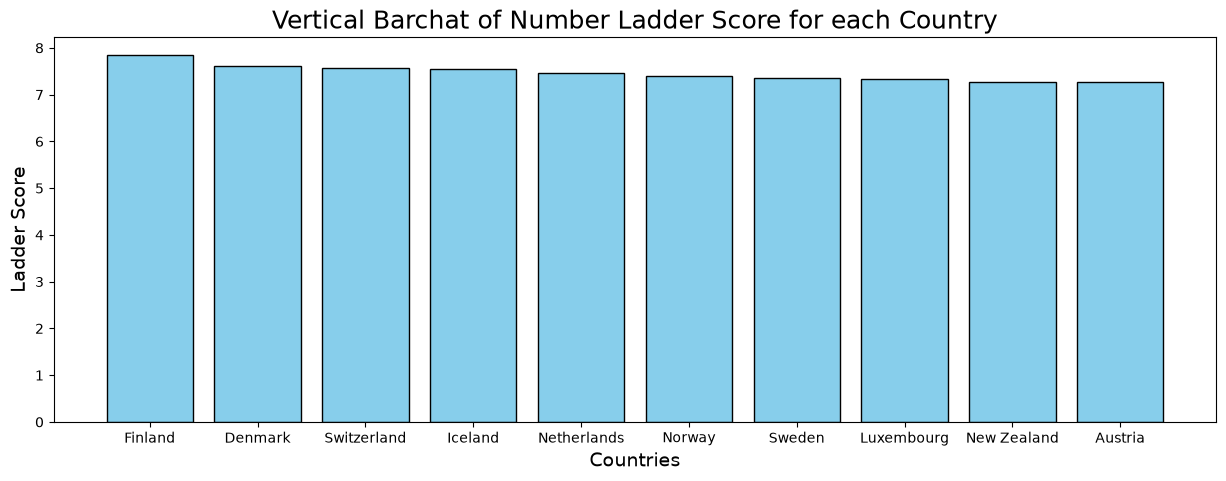

In [ ]:
# VERTICAL BAR CHART:
plt.figure(figsize=(15, 5))
plt.bar(data=df2, x='country',height='lscore', color='skyblue', edgecolor='black')
plt.title("Vertical Barchat of Number Ladder Score for each Country",fontsize=18)
plt.xlabel("Countries",fontsize=14)
plt.ylabel("Ladder Score",fontsize=14)
plt.show()

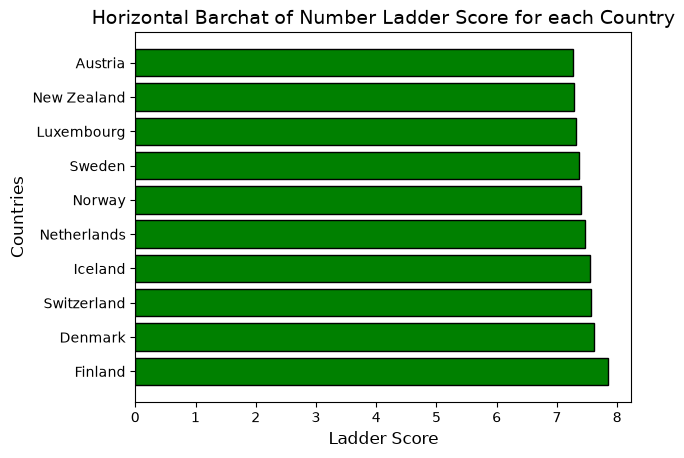

In [ ]:
# HORIZONTAL BAR CHART:
plt.barh(data=df2, y='country',width='lscore', color='green', edgecolor='black')
plt.title("Horizontal Barchat of Number Ladder Score for each Country",fontsize=14)
plt.xlabel("Ladder Score",fontsize=12)
plt.ylabel("Countries",fontsize=12)
plt.show()


## Task: AI statement (mandatory)

Describe here, how did you use AI in this assignment (or mention, if you did not use it at all).:
- Use AI to instruct and explain new codes.



## Task return

File > Save and Export Notebook As > HTML

Then take a look the produced HTML that it looks ok and readable

Return to Itslearning, only the html document is returned, *not* the .ipynb